# ITELv5 - SECCIÓN 7: PRUEBA DEL MODELO (Serving)

En esta sección, cargamos un único audio (WAV) y utilizamos el pipeline completo de ITELv5 (Preproceso, HuBERT y MLP entrenado) para predecir si la voz pertenece a 'Healthy' o 'Patients'.

In [1]:
# 7.1 - Configuración e importaciones
%run "./ITELv5_01_CONFIGURACION.ipynb"

import torch
import torch.nn as nn
import torchaudio
import numpy as np
import pandas as pd
import librosa
import librosa.display
import matplotlib.pyplot as plt
import json
import re
from pathlib import Path
from scipy.signal import butter, filtfilt
from sklearn.preprocessing import StandardScaler

print("✅ Entorno de inferencia listo.")

🔍 Verificando estructura de carpetas...

✅ Estructura de carpetas completa.
🔧 Dependencias comprobadas.

📁 BASE_DIR: C:\Users\USER\Documents\GitHub\ITEL-Tesis-Audio-TEL
🖥️ GPU disponible: False
Rutas Principales de ITELv5:
Datos_Brutos:     C:\Users\USER\Documents\GitHub\ITEL-Tesis-Audio-TEL\Datos_Brutos
Datos Procesados: C:\Users\USER\Documents\GitHub\ITEL-Tesis-Audio-TEL\Datos_Procesados
Modelos:          C:\Users\USER\Documents\GitHub\ITEL-Tesis-Audio-TEL\Modelos
Reportes (CSV):   C:\Users\USER\Documents\GitHub\ITEL-Tesis-Audio-TEL\Reportes\CSV
Reportes (Figuras): C:\Users\USER\Documents\GitHub\ITEL-Tesis-Audio-TEL\Reportes\Figuras
Logs:             C:\Users\USER\Documents\GitHub\ITEL-Tesis-Audio-TEL\Logs
🔍 Carpeta Healthy con 308 subrutas de vocales
🔍 Carpeta Patients con 378 subrutas de vocales
✅ Configuración ITELv5 lista.
✅ Entorno de inferencia listo.


In [2]:
# 7.2 - Definiciones de Funciones y Modelo
# (Copiado de 04_Preprocesamiento, 05_Embeddings y 06_Training)

# --- Parámetros de 04_PREPROCESAMIENTO --- 
TARGET_SR = 16000
HP_CUTOFF = 100
TARGET_DURATION = 2.0

def highpass_filter(y, sr, cutoff=HP_CUTOFF, order=5):
    b, a = butter(order, cutoff / (0.5 * sr), btype='high', analog=False)
    return filtfilt(b, a, y)

def ajustar_duracion(y, sr, target_dur=TARGET_DURATION):
    target_len = int(sr * target_dur)
    if len(y) > target_len:
        start = (len(y) - target_len) // 2
        y = y[start:start + target_len]
    else:
        pad = (target_len - len(y)) // 2
        y = np.pad(y, (pad, target_len - len(y) - pad))
    return y

def procesar_audio(ruta, sr_objetivo=TARGET_SR):
    try:
        y, sr = librosa.load(ruta, sr=None, mono=True)
        if sr != sr_objetivo:
            y = librosa.resample(y, orig_sr=sr, target_sr=sr_objetivo)
            sr = sr_objetivo
        y = highpass_filter(y, sr, cutoff=HP_CUTOFF)
        y = y / np.max(np.abs(y)) if np.max(np.abs(y)) > 0 else y
        y = ajustar_duracion(y, sr)
        return y, sr, 'OK'
    except Exception as e:
        return None, None, f'Error: {e}'

# --- Modelo HuBERT de 05_EMBEDDINGS ---
bundle = torchaudio.pipelines.HUBERT_BASE
hubert_model = bundle.get_model()
hubert_model.eval()
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
hubert_model.to(device)

# --- Función de extracción de 05_EMBEDDINGS ---
def extraer_embedding(ruta):
    y, sr, estado = procesar_audio(ruta)
    if y is None:
        return None
    y = y.astype(np.float32)
    wav_tensor = torch.tensor(y).unsqueeze(0).to(device)
    with torch.inference_mode():
        features, _ = hubert_model(wav_tensor)  # (1, T, 768)
    features = features.squeeze(0)  # (T, 768)
    T = features.shape[0]
    # Mover a CPU antes de operaciones numpy/cat
    features = features.cpu()
    
    mean_emb = features.mean(dim=0)
    std_emb = features.std(dim=0)
    first_25 = features[: max(1, T//4) ].mean(dim=0)
    last_25  = features[- max(1, T//4) :].mean(dim=0)
    delta = first_25 - last_25
    slope_emb = torch.zeros(768)
    x = torch.arange(T, dtype=torch.float32)
    for dim in range(768):
        y_dim = features[:, dim]
        if torch.var(y_dim) == 0 or T < 2:
            slope_emb[dim] = 0
        else:
            slope_emb[dim] = torch.corrcoef(torch.stack([x, y_dim]))[0, 1]
    emb = torch.cat([mean_emb, std_emb, first_25, last_25, delta, slope_emb]).numpy()
    return emb

# --- Clase MLP de 06_TRAINING ---
class MLP(nn.Module):
    def __init__(self, in_dim=4608, hidden=512, dropout=0.3, num_classes=2):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_dim, hidden), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(hidden, hidden//2), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(hidden//2, num_classes)
        )
    def forward(self, x):
        return self.net(x)

print("✅ Funciones de preprocesamiento, extracción y modelo MLP definidas.")

✅ Funciones de preprocesamiento, extracción y modelo MLP definidas.


In [3]:
# 7.3 - Cargar Modelos Entrenados y Scaler

N_SPLITS = 5
models = []
scaler = StandardScaler() # Instanciar scaler

try:
    # 1. Cargar Hiperparámetros del MLP (de 06)
    hparams_path = ITELConfig.MODELS_DIR / 'mlp_hparams_v5.json'
    with open(hparams_path, 'r') as f:
        hparams = json.load(f)
    print(f"Cargando HParams (MLP): {hparams}")

    # 2. Cargar el Scaler (el .npz de 06)
    scaler_path = ITELConfig.MODELS_DIR / 'linear_head_scaler.npz'
    scaler_data = np.load(scaler_path)
    scaler.mean_ = scaler_data['mean']
    scaler.scale_ = scaler_data['scale']
    print(f"Cargando Scaler desde: {scaler_path}")

    # 3. Cargar los 5 modelos MLP (folds de 06)
    for i in range(1, N_SPLITS + 1):
        model_path = ITELConfig.MODELS_DIR / f'itelv5_mlp_fold_{i}.pt'
        model = MLP(
            in_dim=4608, 
            hidden=hparams['hidden'], 
            dropout=hparams['dropout']
        ).to(device)
        model.load_state_dict(torch.load(model_path, map_location=device))
        model.eval()
        models.append(model)
    print(f"✅ {len(models)} modelos MLP (folds) cargados exitosamente.")

except FileNotFoundError as e:
    print(f"⚠️ Error: No se encontró un archivo. {e}")
    print("Asegúrate de haber ejecutado la Sección 6 (Training) completa.")
except Exception as e:
    print(f"Ocurrió un error inesperado: {e}")

Cargando HParams (MLP): {'dropout': 0.5, 'epochs': 100, 'hidden': 256, 'lr': 0.001, 'weight_decay': 1e-05}
Cargando Scaler desde: C:\Users\USER\Documents\GitHub\ITEL-Tesis-Audio-TEL\Modelos\linear_head_scaler.npz
✅ 5 modelos MLP (folds) cargados exitosamente.


In [4]:
# 7.4 - Función de Inferencia (Ensamblaje)

def predecir_audio(ruta_archivo):
    print(f"Procesando: {ruta_archivo}...")
    
    # 1. Extraer embedding (4608 dims)
    embedding = extraer_embedding(ruta_archivo)
    if embedding is None:
        print("Error: No se pudo procesar el audio.")
        return
    
    # 2. Escalar el embedding (debe ser 2D para scaler.transform)
    embedding_scaled = scaler.transform(embedding.reshape(1, -1))
    
    # 3. Convertir a tensor
    emb_tensor = torch.tensor(embedding_scaled, dtype=torch.float32).to(device)

    # 4. Inferencia por Ensamblaje (promediar probas de los 5 modelos)
    all_probas = []
    with torch.inference_mode():
        for model in models:
            logits = model(emb_tensor)
            probas = torch.softmax(logits, dim=1)
            all_probas.append(probas.cpu().numpy())
            
    # Promediar las probabilidades [N_models, 1, N_classes]
    avg_probas = np.mean(np.array(all_probas), axis=0)[0]
    pred_idx = np.argmax(avg_probas)
    confianza = avg_probas[pred_idx]

    # 5. Mapear resultado
    label_map_inv = {0: 'Healthy', 1: 'Patients'}
    resultado = label_map_inv[pred_idx]
    
    print("--- RESULTADO DE LA PREDICCIÓN ---")
    print(f">> Diagnóstico: {resultado} <<")
    print(f"Confianza: {confianza * 100:.2f}%")
    print("----------------------------------")
    print(f"(Proba Healthy: {avg_probas[0]:.3f} | Proba Patients: {avg_probas[1]:.3f})")
    
    # Opcional: Graficar la onda procesada
    y_proc, sr_proc, _ = procesar_audio(ruta_archivo)
    plt.figure(figsize=(10, 3))
    librosa.display.waveshow(y_proc, sr=sr_proc, color='steelblue')
    plt.title(f"Onda procesada (2s, 16kHz) de {Path(ruta_archivo).name}")
    plt.tight_layout()
    plt.show()

In [5]:
# 7.5 - ¡Prueba aquí! Sube tu archivo WAV

import ipywidgets as widgets
from IPython.display import display

print("Por favor, usa el siguiente botón para subir tu archivo WAV:")

# 1. Crear el widget de carga de archivos
uploader = widgets.FileUpload(
    accept='.wav',  # Aceptar solo archivos .wav
    multiple=False  # No permitir subir múltiples archivos
)

# 2. Mostrar el widget
display(uploader)

print("\n...una vez que hayas subido el archivo, ejecuta la siguiente celda (7.6).")

Por favor, usa el siguiente botón para subir tu archivo WAV:


FileUpload(value=(), accept='.wav', description='Upload')


...una vez que hayas subido el archivo, ejecuta la siguiente celda (7.6).


✅ Archivo '4PK1A.wav' recibido.
Procesando: 4PK1A.wav...
--- RESULTADO DE LA PREDICCIÓN ---
>> Diagnóstico: Healthy <<
Confianza: 93.80%
----------------------------------
(Proba Healthy: 0.938 | Proba Patients: 0.062)


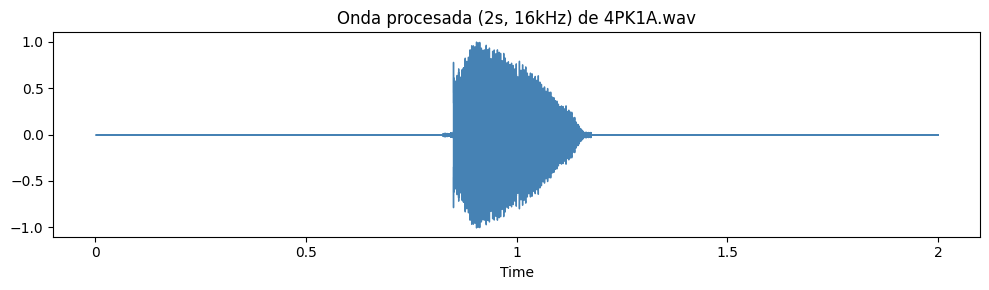

❌ Ocurrió un error al procesar el archivo: The 'value' trait of a FileUpload instance expected a tuple, not the dict {}.


In [7]:
# 7.6 - Procesar el audio subido (Corregido)

# 1. Verificar si se subió un archivo
if not uploader.value:
    print("⚠️ No se ha subido ningún archivo. Por favor, sube un archivo .wav en la celda 7.5 y vuelve a ejecutar esta celda.")
else:
    try:
        # 2. Obtener la información del archivo subido
        file_info = uploader.value[0] # uploader.value es una tupla, tomamos el primer (y único) archivo
        file_name = file_info['name']
        file_content = file_info['content']

        # 3. Guardar el archivo temporalmente en disco para que librosa pueda leerlo
        temp_path = Path(f"./{file_name}")
        with open(temp_path, 'wb') as f:
            f.write(file_content)
        
        print(f"✅ Archivo '{file_name}' recibido.")

        # 4. Llamar a la función de predicción (definida en la celda 7.4)
        predecir_audio(temp_path)
        
        # 5. Opcional: Eliminar el archivo temporal
        temp_path.unlink()

        # 6. Limpiar el widget para la próxima subida (Método correcto)
        uploader.value = {}

    except Exception as e:
        print(f"❌ Ocurrió un error al procesar el archivo: {e}")
        if 'temp_path' in locals() and temp_path.exists():
            temp_path.unlink() # Asegurarse de borrar el temporal si falla